# Práctica 5 - Análisis Exploratorio de Datos (EDA)

**Sesión 5 - Exploración de datos**    
**Herramientas:** Python, pandas y Matplotlib  
**Dataset:** `clientes_ecommerce.csv`

## Objetivos

En esta práctica aprenderás a:

- realizar un análisis exploratorio de un dataset
- estudiar distribuciones numéricas y categóricas
- interpretar media, mediana, cuartiles y desviación estándar
- utilizar histogramas, gráficos de barras, boxplots y diagramas de dispersión
- detectar posibles valores atípicos mediante el IQR
- estudiar relaciones entre variables
- calcular e interpretar correlaciones
- comparar grupos mediante `groupby()` y `crosstab()`
- diferenciar asociación y causalidad
- comunicar hallazgos respaldados por evidencia

> **Importante:** no basta con generar resultados o gráficos. Cada análisis debe ir acompañado de una **interpretación**

## Preparación

Coloca `clientes_ecommerce.csv` en la misma carpeta que este notebook.

Importa NumPy, pandas y Matplotlib y carga el dataset en un DataFrame llamado `df`

In [1]:
# TODO: importa numpy, pandas y matplotlib.pyplot
import numpy as np #arrays operaciones con numeros
import pandas as pd # DataFrame - tablas de datos
import matplotlib.pyplot as plt #graficos

# TODO: carga clientes_ecommerce.csv en un DataFrame llamado df
df = pd.read_csv('clientes_ecommerce.csv')

# Parte 1 - Inspección inicial

## Ejercicio 1

Realiza una inspección inicial:

1. Muestra las primeras 10 filas.
2. Consulta las dimensiones.
3. Muestra los nombres de las columnas.
4. Consulta los tipos de datos.
5. Utiliza `info()`.

In [2]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


In [3]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

In [4]:
# TODO: muestra los nombres de las columnas

for c in df.columns:
    print(c)

cliente_id
edad
antiguedad_meses
ingresos_anuales
gasto_mensual
num_compras
devoluciones
dispositivo
zona
nivel_fidelidad
satisfaccion
compra_proximo_mes


In [5]:
# TODO: consulta los tipos de datos
df.dtypes

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object

In [6]:
# TODO: utiliza info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Responde

1. ¿Cuántas muestras contiene?
2. ¿Cuántas columnas?
3. ¿Cuál es la unidad de observación?
4. ¿Cuál es el identificador?
5. ¿Cuál es el target?
6. ¿Qué columnas tienen valores ausentes?

**Respuesta:**

1. 400.

2. 12.

3. El cliente, cada fila es uno.

4. cliente_id

5. compra_proximo_mes

6. antiguedad_meses, ingresos_anuales y gasto_mensual. Se ve en el info() porque tienen menos de 400 no nulos (395, 396 y 397).

# Parte 2 - Exploración de una variable numérica

Vamos a estudiar `gasto_mensual`.

## Ejercicio 2 - Estadística descriptiva

Obtén el número de valores, media, mediana, desviación estándar, mínimo, \(Q_1\), \(Q_2\), \(Q_3\) y máximo.

In [7]:
# TODO: muestra describe() para gasto_mensual
print(df['gasto_mensual'].describe())

# TODO: calcula las medidas necesarias
print("Mediana: ", df['gasto_mensual'].median())
print("Q1: ", df['gasto_mensual'].quantile(0.25))
print("Q2: ", df['gasto_mensual'].quantile(0.50))
print("Q3: ", df['gasto_mensual'].quantile(0.75))

count    397.000000
mean      69.089320
std       39.023238
min        5.770000
25%       39.720000
50%       61.170000
75%       90.150000
max      260.000000
Name: gasto_mensual, dtype: float64
Mediana:  61.17
Q1:  39.72
Q2:  61.17
Q3:  90.15


### Completa

| Medida | Valor |
|---|---:|
| Número de valores | 397 |
| Media | 69.09 |
| Mediana | 61.17 |
| Desviación estándar | 39.02 |
| Mínimo | 5.77 |
| Q1 | 39.72 |
| Q2 | 61.17 |
| Q3 | 90.15 |
| Máximo | 260 |

### Interpreta

1. ¿Coinciden exactamente media y mediana?
2. ¿Cuál es mayor?
3. ¿Qué puede indicar esta diferencia sobre la distribución?
4. ¿Entre qué valores se encuentra aproximadamente el 50 % central?

**Respuesta:**

1. No.

2. La media, 69.09 frente a 61.17 de la mediana.

3. Que hay algunos clientes que gastan mucho y suben la media, o sea que la distribución tiene cola hacia la derecha.

4. Entre Q1 y Q3, más o menos entre 40 y 90.

# Parte 3 - Visualizar la distribución

## Ejercicio 3 - Histograma

Crea un histograma de `gasto_mensual` utilizando aproximadamente `bins=15`.

Añade título y etiquetas en ambos ejes.

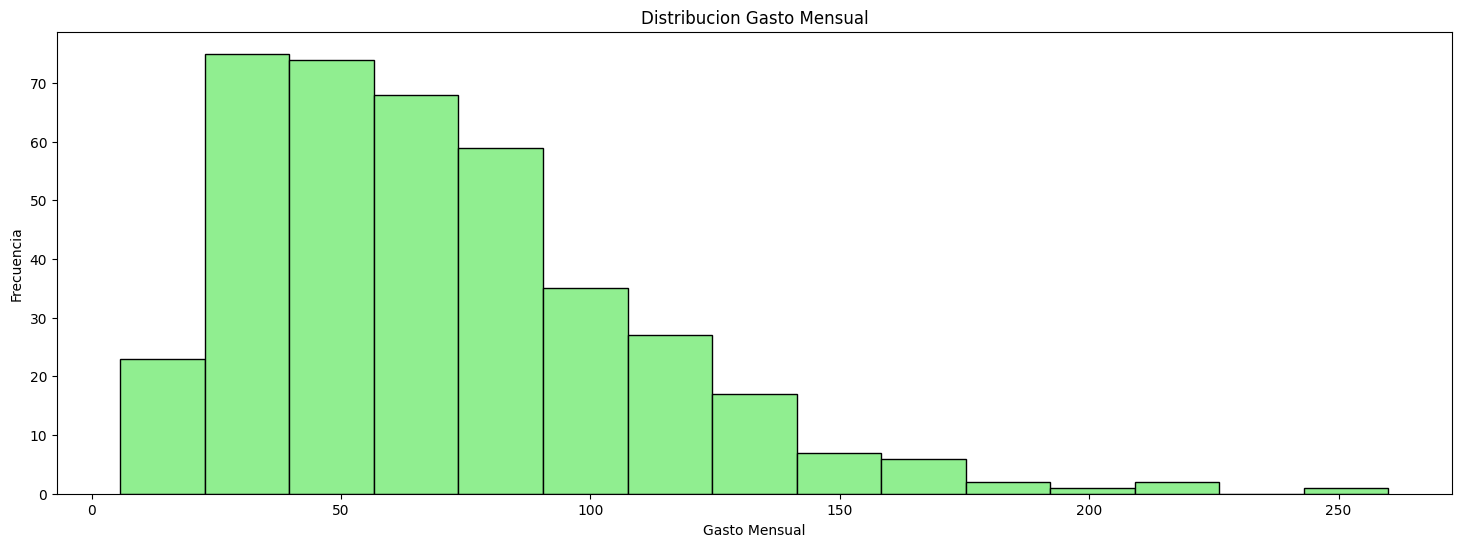

In [8]:
# TODO: crea el histograma de gasto_mensual

plt.figure(figsize=(18,6))
plt.hist(df['gasto_mensual'].dropna(), bins=15, color='lightgreen', edgecolor='black')
plt.xlabel('Gasto Mensual')
plt.ylabel('Frecuencia')
plt.title('Distribucion Gasto Mensual')
plt.show()

### Interpreta

1. ¿Dónde parece concentrarse la mayoría de los clientes?
2. ¿La distribución parece aproximadamente simétrica?
3. ¿Existe una cola hacia valores altos o bajos?
4. ¿Observas valores alejados del resto?

**Respuesta:**

1. La mayoria de los clientes parece concentrarse entre 20 y 90 más o menos.

2. La distribucion es asimétrica. Ya que van decayendo las barras y luego aparecen un par sueltas al final.

3. Existe una cola hacia los valores altos.

4. Observo valores alejados del resto incluso con espacios entre medias.

# Parte 4 - Boxplot y valores atípicos

## Ejercicio 4

Representa `gasto_mensual` mediante un boxplot. Trata adecuadamente los valores ausentes.

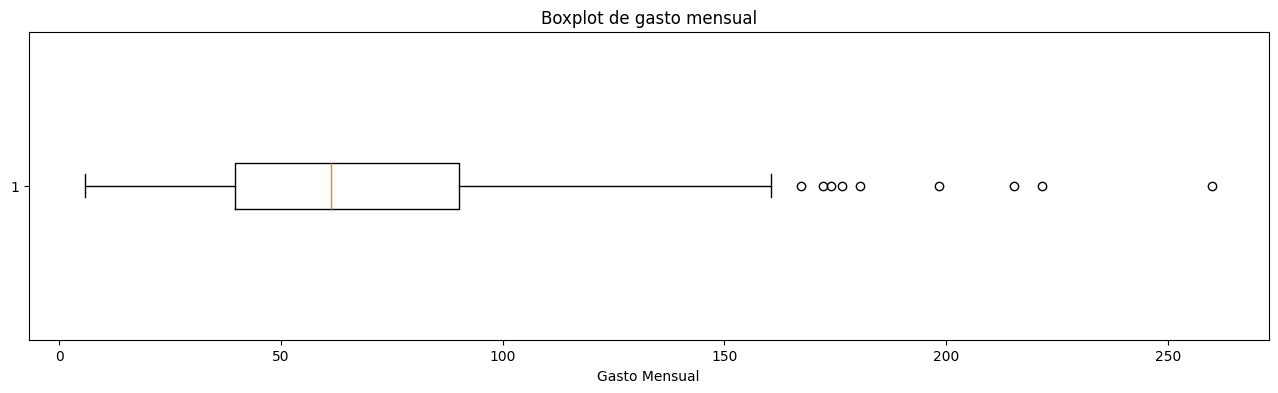

In [9]:
# TODO: crea un boxplot de gasto_mensual
plt.figure(figsize=(16,4))
plt.boxplot(df['gasto_mensual'].dropna(), orientation='horizontal')
plt.xlabel('Gasto Mensual')
plt.title('Boxplot de gasto mensual')
plt.show()

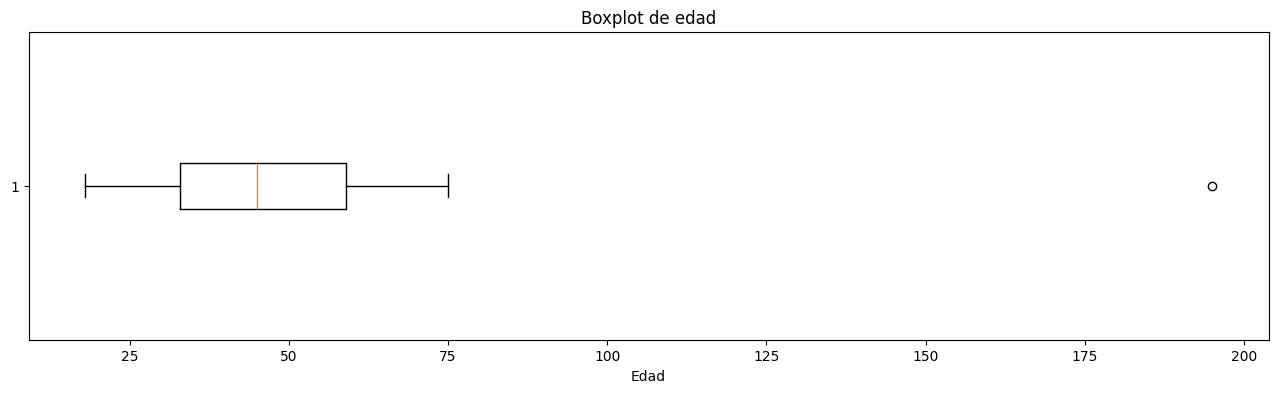

In [10]:
# TODO: crea un boxplot de edad
plt.figure(figsize=(16,4))
plt.boxplot(df['edad'].dropna(), orientation='horizontal')
plt.xlabel('Edad')
plt.title('Boxplot de edad')
plt.show()

In [11]:
Q1 = df['edad'].quantile(0.25)
Q2 = df['edad'].quantile(0.5)
Q3 = df['edad'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Q1: ", Q1)
print("Q2: ", Q2)
print("Q3: ", Q3)
print("IQR: ", IQR)
print("Limite inferior: ", limite_inferior)
print("Limite superior: ", limite_superior)


Q1:  33.0
Q2:  45.0
Q3:  59.0
IQR:  26.0
Limite inferior:  -6.0
Limite superior:  98.0


### Interpreta

1. ¿Dónde se encuentra aproximadamente la mediana?
2. ¿Observas posibles outliers?
3. ¿Aparecen principalmente por encima o por debajo?
4. ¿Podemos afirmar que esos valores son errores únicamente observando el boxplot? Justifica.

**Respuesta:**

1. En el gasto mensual sobre los 61. En la edad en 45.

2. Sí, en el gasto hay varios puntos pasado el bigote derecho, a partir de unos 165. En la edad solo hay uno pero muy lejos, el de 195.

3. Por encima, por debajo no hay ninguno.

4. No. El boxplot solo te dice que están lejos del resto, no si están mal. Alguien puede gastar 200 al mes perfectamente. Lo de la edad de 195 sí es un error, pero eso lo sé porque nadie vive tanto, no por el gráfico.

# Parte 5 - Detectar outliers mediante IQR

## Ejercicio 5

Calcula:

$$
IQR=Q_3-Q_1
$$

y:

$$
L_{inferior}=Q_1-1.5IQR
$$

$$
L_{superior}=Q_3+1.5IQR
$$

Después localiza los clientes cuyo `gasto_mensual` esté fuera de estos límites y guarda el resultado en `outliers_gasto`.

In [12]:
# TODO: calcula Q1, Q3 e IQR
Q1 = df['gasto_mensual'].quantile(0.25)
Q2 = df['gasto_mensual'].quantile(0.50)
Q3 = df['gasto_mensual'].quantile(0.75)
#RANGO INTERCUARTILICO
IQR = Q3 - Q1


# TODO: calcula los límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# TODO: muestra los resultados

print("IQR:", f"{IQR:.2f}", "  Limite inferior:", f"{limite_inferior:.2f}", "  Limite superior:", f"{limite_superior:.2f}")

IQR: 50.43   Limite inferior: -35.93   Limite superior: 165.80


In [13]:
# TODO: crea outliers_gasto

outliers_gasto = df[(df['gasto_mensual'] < limite_inferior) | (df['gasto_mensual'] > limite_superior)]

# limites de la edad (los de arriba son los del gasto)
Q1_edad = df['edad'].quantile(0.25)
Q3_edad = df['edad'].quantile(0.75)
IQR_edad = Q3_edad - Q1_edad
outliers_edad = df[(df['edad'] < Q1_edad - 1.5 * IQR_edad) | (df['edad'] > Q3_edad + 1.5 * IQR_edad)]


# TODO: muestra los posibles outliers

print("Outliers gasto_mensual:", len(outliers_gasto))
display(outliers_gasto)

print("Outliers edad:", len(outliers_edad))
display(outliers_edad)

Outliers gasto_mensual: 9


,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
50,20051,75,49.0,22908.36,176.52,3,1,Móvil,Este,Oro,3,Sí
68,20069,29,78.0,33382.86,215.30,8,2,Móvil,Centro,Bronce,4,No
202,20203,45,57.0,24727.71,167.26,7,4,Móvil,Norte,Platino,1,Sí
203,20204,25,41.0,39329.38,173.91,6,0,Ordenador,Norte,Bronce,2,Sí
207,20208,41,65.0,25812.18,221.59,10,0,Ordenador,Centro,Plata,5,Sí
268,20269,21,61.0,34737.20,198.28,7,2,Tablet,Centro,Bronce,3,Sí
292,20293,20,94.0,31714.55,172.31,13,0,Tablet,Este,Bronce,3,Sí
318,20319,56,38.0,9000.00,180.60,4,0,Ordenador,Este,Bronce,2,Sí
398,20399,75,85.0,40391.73,260.00,10,1,Móvil,Oeste,Bronce,4,Sí


Outliers edad: 1


,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
137,20138,195,106.0,32593.41,138.99,6,0,Móvil,Este,Plata,3,No


### Responde

1. ¿Cuántos posibles outliers has encontrado?
2. ¿Qué porcentaje representan?
3. ¿Cuál es el mayor `gasto_mensual`?
4. ¿Eliminarías automáticamente estas observaciones?
5. ¿Qué investigarías antes?

**Respuesta:**

1. 9 en el gasto mensual, todos por encima de 165.80. En la edad sale 1, el cliente 20138.

2. 9 de 400 es un 2.25%.

3. 260 (cliente 20399).

4. No. Son gastos altos pero pueden ser reales, y me he fijado en que 8 de los 9 compran el mes siguiente, así que quitarlos sería perder información.

5. Si están bien registrados, si son clientes normales o algo tipo empresa, y si el 260 es un tope del sistema, porque es un número muy redondo.

# Parte 6 - Comparar varias distribuciones

## Ejercicio 6

Analiza:

- `edad`
- `ingresos_anuales`
- `gasto_mensual`
- `num_compras`
- `devoluciones`

Consulta sus estadísticas descriptivas y crea un histograma independiente para cada variable.

In [14]:
# TODO: consulta las estadísticas descriptivas de las variables indicadas
print(df[['edad', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones']].describe())

             edad  ingresos_anuales  gasto_mensual  num_compras  devoluciones
count  400.000000        396.000000     397.000000   400.000000    400.000000
mean    46.402500      36440.920379      69.089320     8.225000      1.225000
std     18.007809      14325.228166      39.023238     2.780955      1.136929
min     18.000000       9000.000000       5.770000     2.000000      0.000000
25%     33.000000      26034.092500      39.720000     6.000000      0.000000
50%     45.000000      36817.275000      61.170000     8.000000      1.000000
75%     59.000000      45969.032500      90.150000    10.000000      2.000000
max    195.000000      82925.370000     260.000000    17.000000      5.000000


In [15]:
# TODO: calcula sus medianas
print(df[['edad', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones']].median())

edad                   45.000
ingresos_anuales    36817.275
gasto_mensual          61.170
num_compras             8.000
devoluciones            1.000
dtype: float64


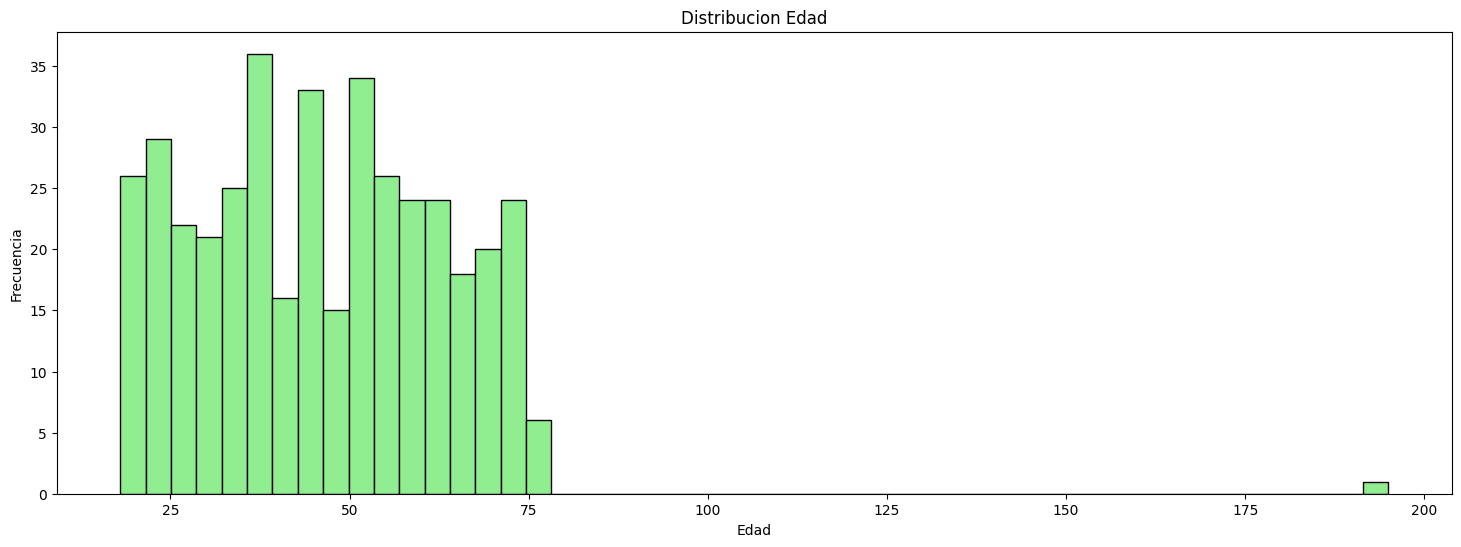

In [16]:
# TODO: histograma de edad

plt.figure(figsize=(18,6))
plt.hist(df['edad'], bins=50, color='lightgreen', edgecolor='black')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.title('Distribucion Edad')
plt.show()

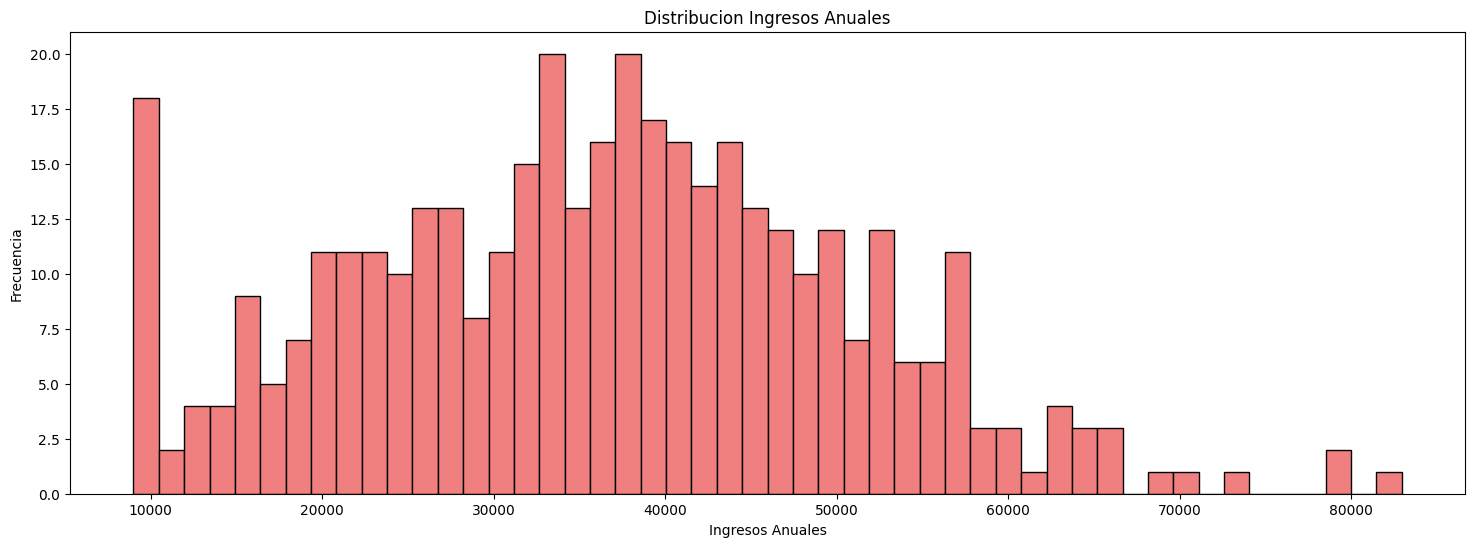

In [17]:
# TODO: histograma de ingresos_anuales


plt.figure(figsize=(18,6))
plt.hist(df['ingresos_anuales'].dropna(), bins=50, color='lightcoral', edgecolor='black')
plt.xlabel('Ingresos Anuales')
plt.ylabel('Frecuencia')
plt.title('Distribucion Ingresos Anuales')
plt.show()

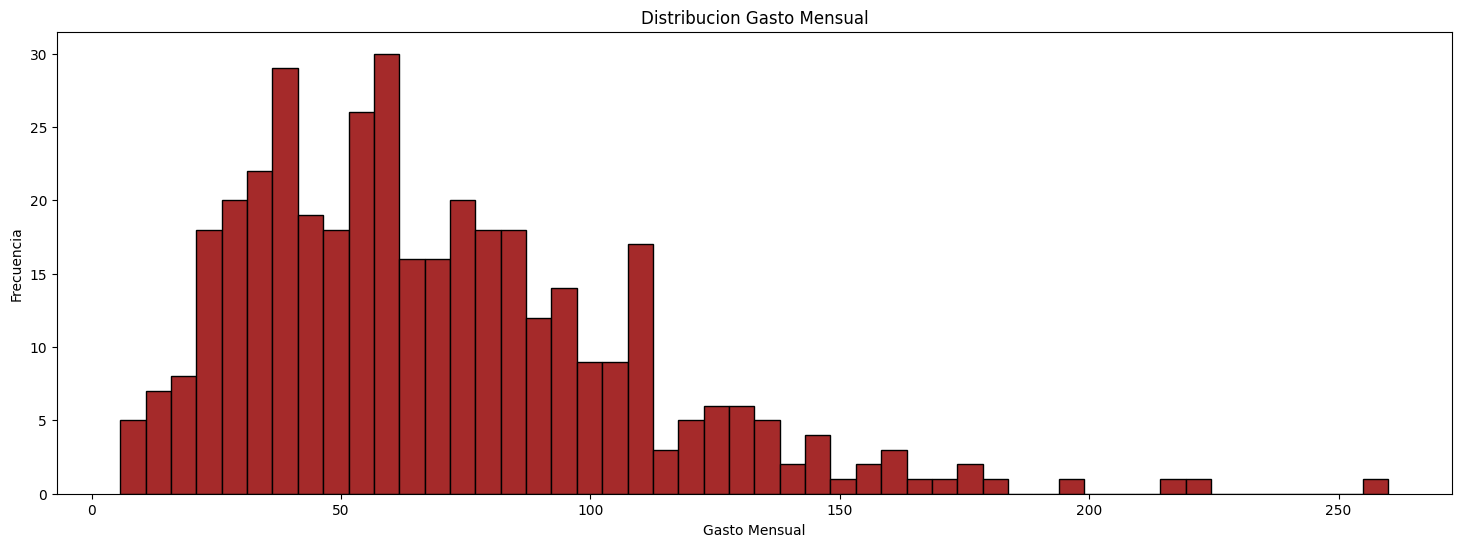

In [18]:
# TODO: histograma de gasto_mensual

plt.figure(figsize=(18,6))
plt.hist(df['gasto_mensual'].dropna(), bins=50, color='brown', edgecolor='black')
plt.xlabel('Gasto Mensual')
plt.ylabel('Frecuencia')
plt.title('Distribucion Gasto Mensual')
plt.show()

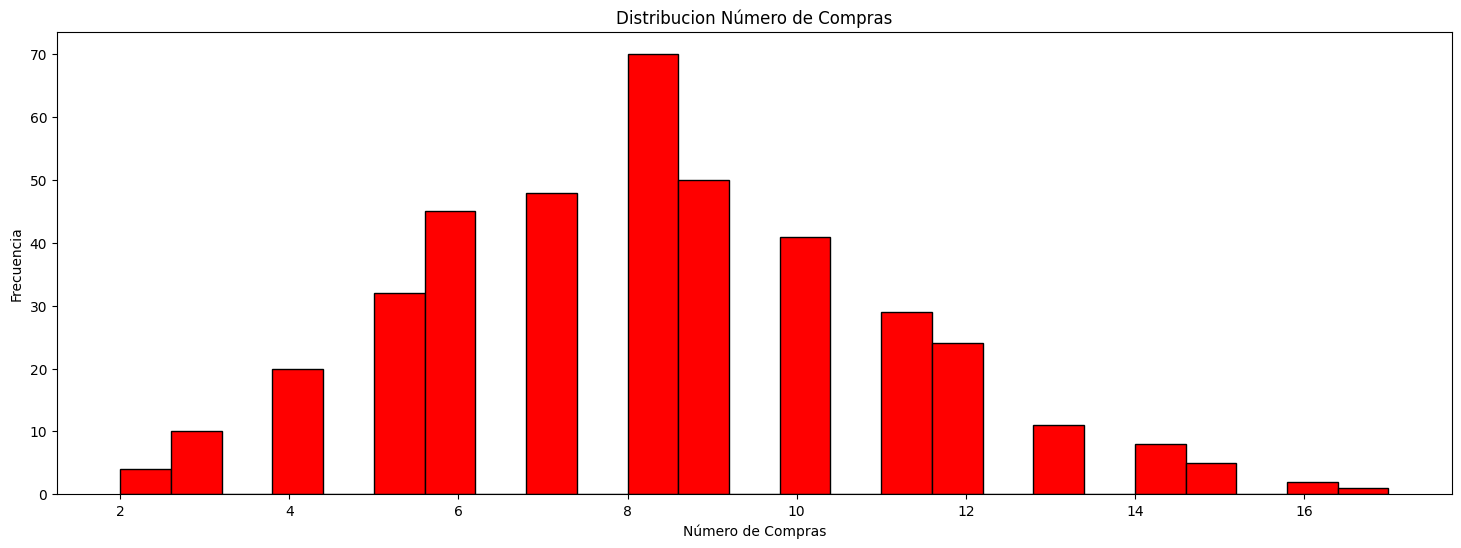

In [19]:
# TODO: histograma de num_compras

plt.figure(figsize=(18,6))
plt.hist(df['num_compras'], bins=25, color='red', edgecolor='black')
plt.xlabel('Número de Compras')
plt.ylabel('Frecuencia')
plt.title('Distribucion Número de Compras')
plt.show()

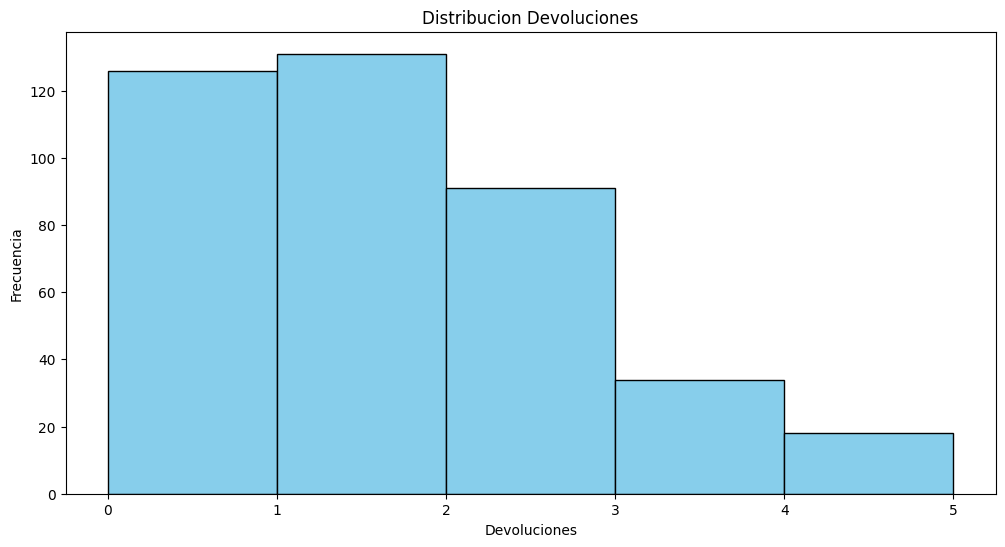

In [20]:
# TODO: histograma de devoluciones

plt.figure(figsize=(12,6))
plt.hist(df['devoluciones'], bins=5, color='skyblue', edgecolor='black')
plt.xlabel('Devoluciones')
plt.ylabel('Frecuencia')
plt.title('Distribucion Devoluciones')
plt.show()

### Completa

| Variable | Media | Mediana | Mínimo | Máximo | Observación relevante |
|---|---:|---:|---:|---:|---|
| edad | 46.40 | 45 | 18 | 195 | El 195 es imposible, sin él el máximo sería 75 |
| ingresos_anuales | 36440.92 | 36817.27 | 9000 | 82925.37 | Bastante simétrica, pero hay muchos clientes con 9000 justos |
| gasto_mensual | 69.09 | 61.17 | 5.77 | 260 | Cola a la derecha y varios outliers |
| num_compras | 8.22 | 8 | 2 | 17 | Bastante simétrica, casi todos entre 6 y 10 |
| devoluciones | 1.23 | 1 | 0 | 5 | La mayoría hace 0, 1 o 2 |

### Busca una observación sospechosa

- ¿Qué variable es?
- ¿Qué valor tiene?
- ¿Por qué parece sospechoso?
- ¿Es un outlier?
- ¿Podemos afirmar directamente que es un error?
- ¿Qué harías antes de modificarlo?

**Respuesta:**

La variable es la edad y el valor es 195 (cliente 20138). Es sospechoso porque nadie tiene 195 años y el resto de clientes están entre 18 y 75. Sí es un outlier, el límite superior de la edad es 98. Casi seguro que es un error, pero no sabemos cuál era el valor de verdad (podría ser 19, 95...), así que no lo cambiaría a ojo. Primero miraría el dato original y si no se puede saber lo pondría como NaN para imputarlo después, en vez de borrar al cliente.

# Parte 7 - Variables categóricas

## Ejercicio 7 - Frecuencias

Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes`.

Calcula frecuencias absolutas, relativas y porcentajes mediante `value_counts()`.

In [21]:
# TODO: analiza dispositivo
print(df['dispositivo'].value_counts())
print(df['dispositivo'].value_counts(normalize=True))

dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        0.6050
Ordenador    0.3325
Tablet       0.0625
Name: proportion, dtype: float64


In [22]:

# TODO: analiza zona
absolutas = df['zona'].value_counts()
relativas = df['zona'].value_counts(normalize=True)
porcentajes = (relativas * 100).round(2)

pd.DataFrame({'Frecuencia absoluta': absolutas,
              'Frecuencia relativa': relativas.round(4),
              'Porcentaje (%)': porcentajes})

,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%)
zona,,,
Este,89,0.2225,22.25
Sur,80,0.2000,20.00
Norte,79,0.1975,19.75
Oeste,76,0.1900,19.00
Centro,76,0.1900,19.00


In [23]:
# TODO: analiza nivel_fidelidad
absolutas = df['nivel_fidelidad'].value_counts()
relativas = df['nivel_fidelidad'].value_counts(normalize=True)
porcentajes = (relativas * 100).round(2)

pd.DataFrame({'Frecuencia absoluta': absolutas,
              'Frecuencia relativa': relativas.round(4),
              'Porcentaje (%)': porcentajes})

,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%)
nivel_fidelidad,,,
Bronce,162,0.4050,40.50
Plata,105,0.2625,26.25
Oro,83,0.2075,20.75
Platino,50,0.1250,12.50


In [24]:
# TODO: analiza compra_proximo_mes
absolutas = df['compra_proximo_mes'].value_counts()
relativas = df['compra_proximo_mes'].value_counts(normalize=True)
porcentajes = (relativas * 100).round(2)

pd.DataFrame({'Frecuencia absoluta': absolutas,
              'Frecuencia relativa': relativas.round(4),
              'Porcentaje (%)': porcentajes})

,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%)
compra_proximo_mes,,,
No,246,0.615,61.5
Sí,154,0.385,38.5


### Completa

| Variable | Categoría más frecuente | Nº muestras | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60.5% |
| zona | Este | 89 | 22.25% |
| nivel_fidelidad | Bronce | 162 | 40.5% |
| compra_proximo_mes | No | 246 | 61.5% |

# Parte 8 - Visualización de variables categóricas

## Ejercicio 8

Crea gráficos de barras independientes para:

- `dispositivo`
- `nivel_fidelidad`
- `compra_proximo_mes`

Todos deben incluir título y etiquetas.

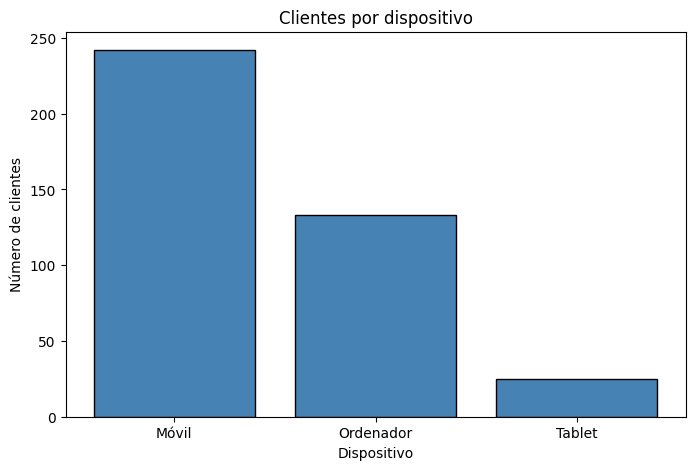

In [25]:
# TODO: gráfico de barras de dispositivo
conteo = df['dispositivo'].value_counts()

plt.figure(figsize=(8,5))
plt.bar(conteo.index, conteo.values, color='steelblue', edgecolor='black')
plt.xlabel('Dispositivo')
plt.ylabel('Número de clientes')
plt.title('Clientes por dispositivo')
plt.show()

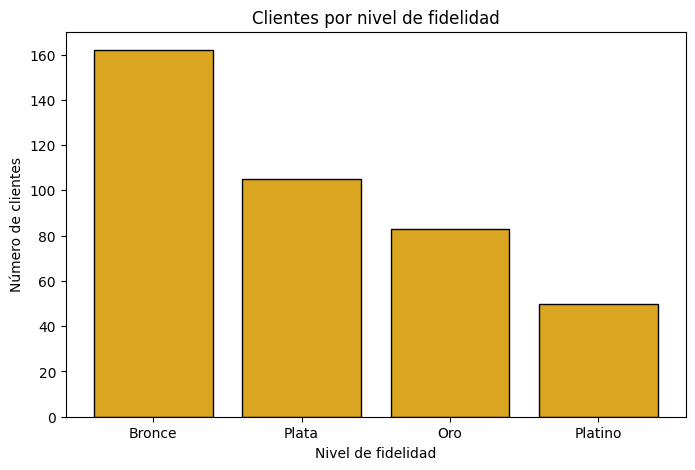

In [26]:
# TODO: gráfico de barras de nivel_fidelidad
orden = ['Bronce', 'Plata', 'Oro', 'Platino']
conteo = df['nivel_fidelidad'].value_counts().reindex(orden)

plt.figure(figsize=(8,5))
plt.bar(conteo.index, conteo.values, color='goldenrod', edgecolor='black')
plt.xlabel('Nivel de fidelidad')
plt.ylabel('Número de clientes')
plt.title('Clientes por nivel de fidelidad')
plt.show()

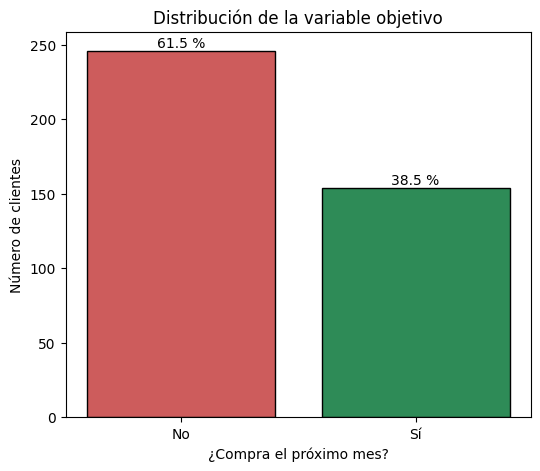

In [27]:
# TODO: gráfico de barras de compra_proximo_mes
conteo = df['compra_proximo_mes'].value_counts()

plt.figure(figsize=(6,5))
plt.bar(conteo.index, conteo.values, color=['indianred', 'seagreen'], edgecolor='black')
plt.xlabel('¿Compra el próximo mes?')
plt.ylabel('Número de clientes')
plt.title('Distribución de la variable objetivo')

# Añade el porcentaje encima de cada barra
for i, v in enumerate(conteo.values):
    plt.text(i, v + 2, f'{v / conteo.sum() * 100:.1f} %', ha='center')

plt.show()

### Interpreta

Escribe al menos una conclusión sobre cada gráfico.

Para `compra_proximo_mes`, responde además:

> ¿Las clases están perfectamente equilibradas?

Justifica utilizando porcentajes.

**Respuesta:**

- Dispositivo: casi todos compran desde el móvil (60.5%), luego ordenador (33.25%) y la tablet casi no se usa (6.25%).

- Nivel de fidelidad: cuanto más alto el nivel menos clientes hay. Bronce tiene el 40.5% y Platino solo el 12.5%.

- Compra el próximo mes: no están equilibradas. El 61.5% no compra y el 38.5% sí. No es una diferencia enorme pero hay bastantes más "No".

# Parte 9 - Relación entre dos variables numéricas

Queremos investigar:

> **¿Existe alguna relación entre el número de compras realizadas y el gasto mensual?**

## Ejercicio 9 - Scatter plot

Representa:

$$
X=\text{num\_compras}
$$

$$
Y=\text{gasto\_mensual}
$$

mediante un diagrama de dispersión.

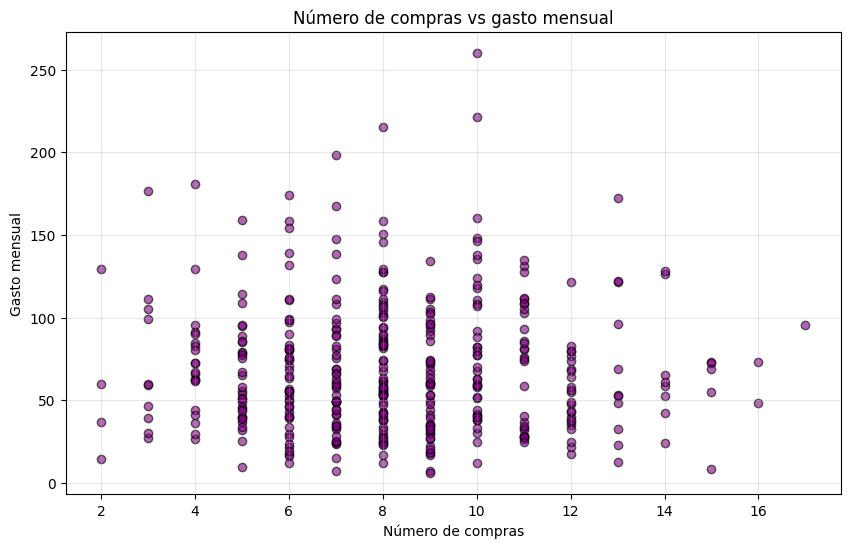

In [28]:
# TODO: crea un scatter plot de num_compras frente a gasto_mensual
plt.figure(figsize=(10,6))
plt.scatter(df['num_compras'], df['gasto_mensual'], alpha=0.6, color='purple', edgecolor='black')
plt.xlabel('Número de compras')
plt.ylabel('Gasto mensual')
plt.title('Número de compras vs gasto mensual')
plt.grid(alpha=0.3)
plt.show()

### Antes de calcular la correlación

1. ¿Parece existir una relación?
2. ¿Parece positiva o negativa?
3. ¿Parece fuerte o débil?
4. ¿Observas muestras especialmente alejadas?

**Respuesta:**

1. A simple vista no, los puntos están todos mezclados.

2. No se ve ninguna de las dos.

3. Si hay algo, muy débil.

4. Sí, unos cuantos clientes con gasto muy alto arriba del todo (más de 160).

# Parte 10 - Correlación

## Ejercicio 10

Calcula la correlación entre `num_compras` y `gasto_mensual` utilizando `corr()`.

In [29]:
# TODO: calcula la correlación entre num_compras y gasto_mensual
df[['num_compras', 'gasto_mensual']].corr()


,num_compras,gasto_mensual
num_compras,1.000000,-0.014165
gasto_mensual,-0.014165,1.000000


### Interpreta

1. ¿Cuál es el valor de \(r\)?
2. ¿Es positivo o negativo?
3. ¿Qué significa el signo?
4. ¿Coincide con lo observado en el scatter plot?
5. ¿Podemos afirmar que realizar más compras **provoca** un mayor gasto mensual? Justifica.

**Respuesta:**

1. -0.014

2. Negativo, pero es prácticamente 0.

3. Si fuera negativo de verdad querría decir que cuando sube una baja la otra. Aquí es tan pequeño que no significa nada.

4. Sí, en el gráfico tampoco se veía relación.

5. No. Primero porque la correlación es casi 0, y aunque fuera alta, correlación no es causalidad.

# Parte 11 - Matriz de correlaciones

## Ejercicio 11

Selecciona las variables numéricas y calcula su matriz de correlaciones.

> **Atención:** `cliente_id` es técnicamente numérico, pero conceptualmente es un identificador. No debes incluirlo.

In [30]:
# TODO: selecciona las variables numéricas excluyendo cliente_id

numericas = df.select_dtypes(include=[np.number]).drop(columns=['cliente_id'])

# TODO: calcula y muestra la matriz de correlaciones

correlaciones = numericas.corr()
correlaciones


,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,satisfaccion
edad,1.000000,0.031192,-0.036610,0.021361,-0.077583,-0.097102,-0.062801
antiguedad_meses,0.031192,1.000000,-0.058738,0.006482,-0.099965,-0.056458,-0.040051
ingresos_anuales,-0.036610,-0.058738,1.000000,-0.000367,0.072991,0.000260,-0.062595
gasto_mensual,0.021361,0.006482,-0.000367,1.000000,-0.014165,0.030674,-0.054523
num_compras,-0.077583,-0.099965,0.072991,-0.014165,1.000000,-0.005747,0.092211
devoluciones,-0.097102,-0.056458,0.000260,0.030674,-0.005747,1.000000,0.030817
satisfaccion,-0.062801,-0.040051,-0.062595,-0.054523,0.092211,0.030817,1.000000


### Interpreta

1. ¿Por qué todos los valores de la diagonal son 1?
2. ¿Por qué la matriz es simétrica?
3. Sin considerar la diagonal, ¿qué pareja presenta la correlación positiva más alta?
4. ¿Qué pareja presenta la correlación más negativa?
5. ¿Hay variables cuya correlación sea prácticamente cero?

**Respuesta:**

1. Porque es cada variable comparada consigo misma.

2. Porque la correlación de A con B es la misma que la de B con A.

3. num_compras y satisfaccion, con 0.092. Aun así es muy baja.

4. antiguedad_meses y num_compras, con -0.10.

5. Sí, muchas. Por ejemplo ingresos_anuales con gasto_mensual o con devoluciones salen 0.000 y algo. En general todas son muy bajas, ninguna pasa de 0.1.

# Parte 12 - Visualizar las correlaciones

## Ejercicio 12

Representa la matriz mediante `plt.imshow()`.

Añade nombres de variables en ambos ejes, barra de color y título.

range(0, 7)


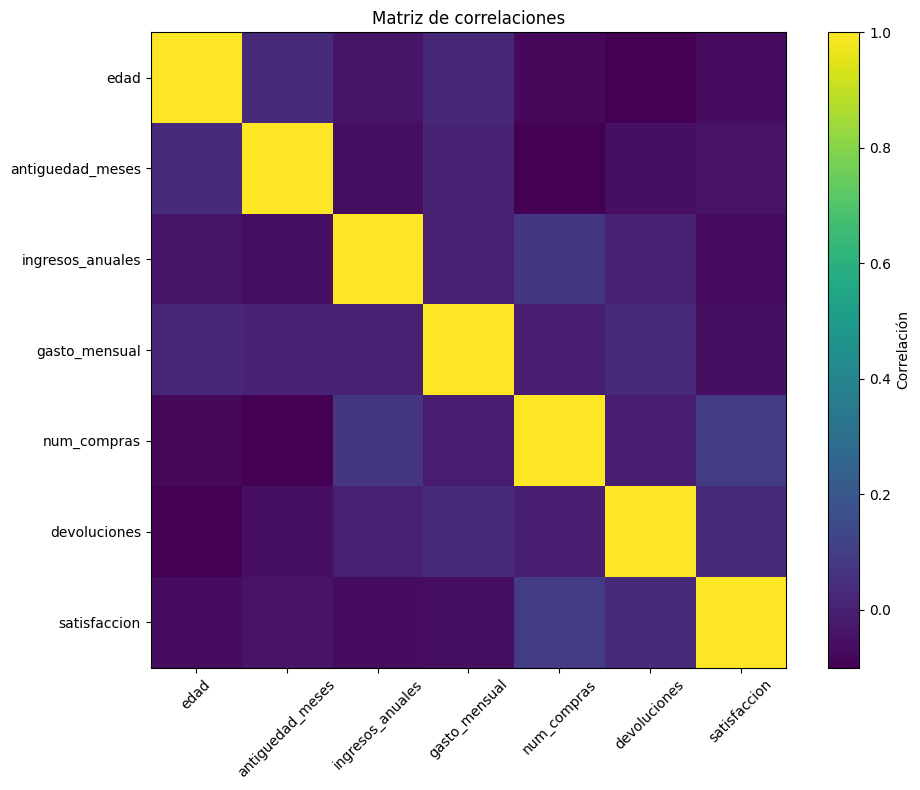

In [31]:
# TODO: representa la matriz de correlaciones con plt.imshow()
plt.figure(figsize=(10,8))
plt.imshow(correlaciones)
print(range(len(correlaciones.columns)))
plt.xticks(range(len(correlaciones.columns)), correlaciones.columns, rotation=45)
plt.yticks(range(len(correlaciones.columns)), correlaciones.columns)
plt.colorbar(label='Correlación')
plt.title('Matriz de correlaciones')
plt.tight_layout()
plt.show()

### Interpreta tres relaciones

Selecciona tres relaciones de la matriz y explica qué significa cada valor.

1. ingresos_anuales y gasto_mensual (casi 0): no tienen relación. Me ha sorprendido porque pensaba que quien gana más gastaría más.
2. antiguedad_meses y num_compras (-0.10): muy débil y negativa. Los clientes más antiguos comprarían un poco menos, pero es tan poco que no se puede decir mucho.
3. num_compras y satisfaccion (0.09): muy débil y positiva. Los más satisfechos comprarían un pelín más.

Recuerda:

$$
\boxed{\text{correlación}\neq\text{causalidad}}
$$

# Parte 13 - Variable numérica frente a categórica

Queremos investigar:

> **¿Los clientes que realizan una compra el mes siguiente presentan un gasto histórico diferente?**

## Ejercicio 13

Utiliza `groupby()` para obtener para cada valor de `compra_proximo_mes`:

- número de clientes
- gasto medio
- mediana
- desviación estándar.

In [32]:
# TODO: agrupa por compra_proximo_mes y calcula las estadísticas solicitadas

df.groupby('compra_proximo_mes')["gasto_mensual"].agg(
    numero_clientes = "count",
    gasto_mensual = "mean",
    mediana ="median",
    desviacion_tipica = "std"
)

,numero_clientes,gasto_mensual,mediana,desviacion_tipica
compra_proximo_mes,,,,
No,245,64.589469,59.28,33.693480
Sí,152,76.342368,66.50,45.534042


In [33]:
df.groupby('nivel_fidelidad')["ingresos_anuales"].agg(
    numero_clientes = "count",
    ingresos_medios = "mean",
    mediana ="median",
    desviacion_tipica = "std"
)

,numero_clientes,ingresos_medios,mediana,desviacion_tipica
nivel_fidelidad,,,,
Bronce,162,36409.247963,37028.050,13261.941850
Oro,83,35921.890843,36831.090,14873.491333
Plata,103,37097.991068,37994.140,14716.674654
Platino,48,36035.339167,34151.525,16266.443749


### Interpreta

1. ¿Qué grupo presenta mayor gasto medio?
2. ¿Y mayor mediana?
3. ¿Las diferencias parecen grandes o pequeñas?
4. ¿La media y la mediana cuentan exactamente la misma historia?

**Respuesta:**

1. Los que sí compran, 76.34 frente a 64.59.

2. También los que sí compran, 66.50 frente a 59.28.

3. Ni muy grandes ni muy pequeñas, unos 12 de diferencia en la media y 7 en la mediana.

4. Más o menos, las dos dicen que el grupo "Sí" gasta más. Pero en la media la diferencia es mayor porque en el grupo "Sí" hay más gente con gastos muy altos (su desviación es 45 frente a 34).

# Parte 14 - Comparación visual entre grupos

## Ejercicio 14

Crea:

- `grupo_no`: gasto mensual de quienes no compran el mes siguiente
- `grupo_si`: gasto mensual de quienes sí compran.

Representa ambos mediante un único boxplot.

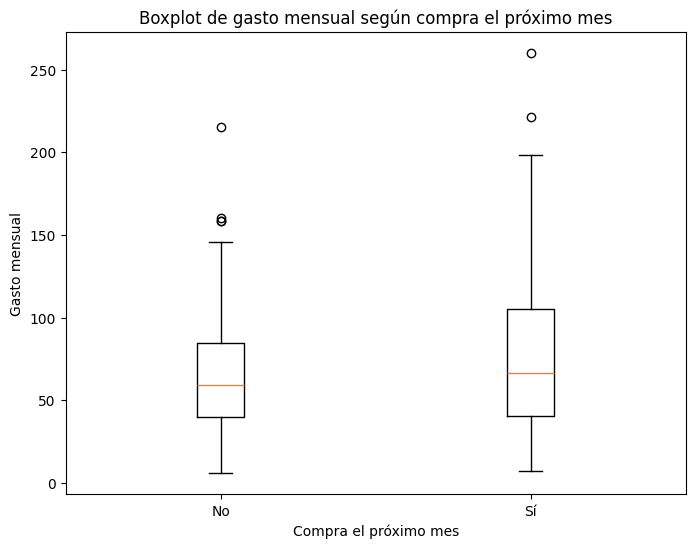

In [34]:
# TODO: crea grupo_no y grupo_si

grupo_no = df.loc[df['compra_proximo_mes'] == 'No', 'gasto_mensual'].dropna()
grupo_si = df.loc[df['compra_proximo_mes'] == 'Sí', 'gasto_mensual'].dropna()
plt.figure(figsize=(8,6))
plt.boxplot([grupo_no, grupo_si], tick_labels=['No', 'Sí'])
plt.xlabel('Compra el próximo mes')
plt.ylabel('Gasto mensual')
plt.title('Boxplot de gasto mensual según compra el próximo mes')
plt.show()



# TODO: representa ambos grupos mediante un boxplot


### Interpreta

1. ¿Qué grupo presenta una mediana mayor?
2. ¿Cuál parece tener mayor dispersión?
3. ¿Existen outliers en ambos?
4. ¿El gráfico apoya las conclusiones obtenidas mediante `groupby()`?

**Respuesta:**

1. El de "Sí".

2. También el de "Sí", la caja es más grande y el bigote llega más arriba.

3. Sí, en "No" salen 4 y en "Sí" 2 (los de 221 y 260).

4. Sí, se ve lo mismo, los que compran gastaban algo más y están más dispersos.

# Parte 15 - Dos variables categóricas

Queremos responder:

> **¿La proporción de compra es igual para todos los niveles de fidelidad?**

## Ejercicio 15

Crea:

1. una tabla de contingencia con frecuencias absolutas
2. una tabla normalizada por filas mediante `normalize="index"`
3. una versión expresada en porcentajes.

In [35]:
# TODO: tabla de contingencia con frecuencias absolutas
frecuencias_absolutas = pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'])
frecuencias_absolutas


compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,112,50
Oro,52,31
Plata,63,42
Platino,19,31


In [36]:
# TODO: tabla normalizada por filas
frecuencias = pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'],normalize='index')
frecuencias


compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,0.691358,0.308642
Oro,0.626506,0.373494
Plata,0.600000,0.400000
Platino,0.380000,0.620000


In [37]:
# TODO: muestra las proporciones como porcentajes
(frecuencias * 100).round(2)

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,69.14,30.86
Oro,62.65,37.35
Plata,60.00,40.00
Platino,38.00,62.00


### Interpreta

1. ¿Qué nivel tiene mayor número absoluto de clientes que compran?
2. ¿Qué nivel tiene mayor porcentaje de clientes que compran?
3. ¿Coinciden necesariamente ambas respuestas?
4. ¿Por qué son importantes las proporciones cuando los grupos tienen tamaños diferentes?

**Respuesta:**

1. Bronce, 50 clientes.

2. Platino, el 62%.

3. No, y aquí se ve. Bronce tiene más compradores solo porque es el grupo más grande, pero en porcentaje es el que menos compra (30.86%).

4. Porque si un grupo es mucho más grande es normal que tenga más de todo. Con porcentajes puedes comparar grupos de distinto tamaño.

# Parte 16 - Correlación no implica causalidad

## Ejercicio 16 - Razonamiento

Un compañero observa una relación entre `nivel_fidelidad` y `compra_proximo_mes` y afirma:

> **«Subir a un cliente al nivel Platino hará que compre el próximo mes».**

¿Es correcta esta conclusión?

Redacta entre **5 y 8 líneas** utilizando correctamente:

- asociación
- causalidad
- variables adicionales
- evidencia

### Respuesta

No es correcta. Lo que vemos es una asociación, en Platino compra el 62% y en Bronce el 30.86%, pero eso no demuestra causalidad. Puede ser al revés, que los clientes lleguen a Platino justo porque ya compran mucho. También puede haber variables adicionales que no tenemos y que influyen en las dos cosas, como las promociones que recibe cada cliente o lo mucho que entra en la web. Además en Platino solo hay 50 clientes. Para tener evidencia de verdad habría que hacer una prueba, por ejemplo subir de nivel a unos clientes al azar y compararlos con otros que se queden igual.

# Parte 17 - Investiga una hipótesis

## Ejercicio 17

Elige **una**:

**A.** ¿Los clientes con mayores ingresos gastan más mensualmente?  
**B.** ¿Los clientes más antiguos realizan más compras?  
**C.** ¿La satisfacción está relacionada con el número de compras?  
**D.** ¿El número de devoluciones está relacionado con la satisfacción?

Realiza:

1. selección de variables
2. estadística descriptiva
3. visualización adecuada
4. correlación si procede
5. interpretación.

       satisfaccion  num_compras
count    400.000000   400.000000
mean       3.330000     8.225000
std        1.165975     2.780955
min        1.000000     2.000000
25%        3.000000     6.000000
50%        3.000000     8.000000
75%        4.000000    10.000000
max        5.000000    17.000000

              count      mean  median       std
satisfaccion                                   
1                33  7.939394     8.0  2.771951
2                58  7.068966     6.5  2.383143
3               123  8.552846     8.0  2.829016
4               116  8.560345     8.0  2.621943
5                70  8.185714     8.0  3.051694


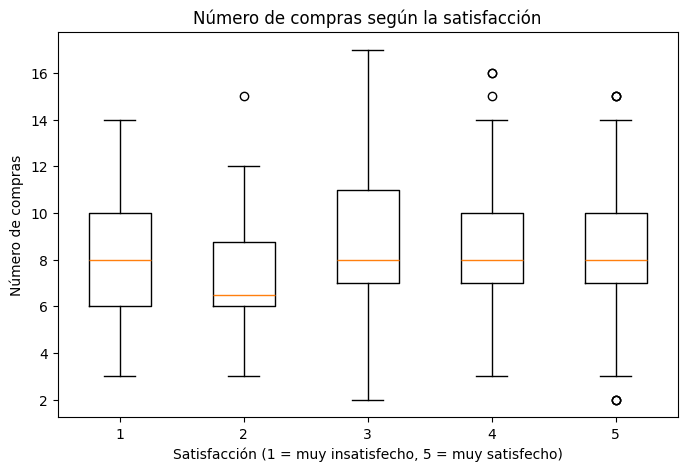

Pearson: 0.09221131622535975
Spearman: 0.09371725124099678


In [38]:
# TODO: desarrolla aquí el análisis de la hipótesis seleccionada
# Hipótesis C: ¿La satisfacción está relacionada con el número de compras?

# 1. selección de variables
hip = df[['satisfaccion', 'num_compras']]

# 2. estadística descriptiva
print(hip.describe())
print()
print(df.groupby('satisfaccion')['num_compras'].agg(['count', 'mean', 'median', 'std']))

# 3. visualización
niveles = sorted(df['satisfaccion'].unique())
grupos = [df.loc[df['satisfaccion'] == n, 'num_compras'] for n in niveles]

plt.figure(figsize=(8,5))
plt.boxplot(grupos, tick_labels=niveles)
plt.xlabel('Satisfacción (1 = muy insatisfecho, 5 = muy satisfecho)')
plt.ylabel('Número de compras')
plt.title('Número de compras según la satisfacción')
plt.show()

# 4. correlación (también spearman porque satisfaccion es ordinal)
print("Pearson:", hip.corr().iloc[0, 1])
print("Spearman:", hip.corr(method='spearman').iloc[0, 1])

### Conclusión de la hipótesis

Redacta entre **5 y 10 líneas**. No escribas únicamente el valor de correlación.

**Respuesta:**
He elegido la C. La satisfacción va de 1 a 5 y casi todos están en 3 o 4, y el número de compras va de 2 a 17 con una media de 8.22. Agrupando por satisfacción, los de 3 y 4 hacen unas 8.5 compras de media, los de 2 bajan a 7.07 y los de 1 y 5 se quedan en 7.94 y 8.19. O sea, que los más satisfechos no compran más que los que están en el medio. En el boxplot las cajas de todos los niveles son casi iguales. La correlación sale 0.092 (Pearson) y 0.094 (Spearman), positiva pero muy débil. Mi conclusión es que en estos datos la satisfacción y el número de compras casi no tienen relación. Y aunque la tuvieran, no sabríamos cuál influye en cuál.

# Parte 18 - El reto del analista

## Ejercicio 18

Trabaja ahora con mayor autonomía:

> **¿Qué características parecen diferenciar a los clientes que compran el mes siguiente de los que no compran?**

Puedes investigar:

`edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad` y `satisfaccion`.

Tu análisis debe contener como mínimo:

- una comparación numérica
- una comparación categórica
- dos visualizaciones
- estadísticas descriptivas
- una tabla de proporciones.

In [39]:
# TODO: comparación numérica
variables_num = ['edad', 'antiguedad_meses', 'ingresos_anuales', 'gasto_mensual',
                 'num_compras', 'devoluciones', 'satisfaccion']

df.groupby('compra_proximo_mes')[variables_num].agg(['mean', 'median']).round(2).T

compra_proximo_mes             No        Sí
edad             mean       47.81     44.15
                 median     47.50     44.00
antiguedad_meses mean       59.47     60.46
                 median     59.00     60.50
ingresos_anuales mean    36457.79  36413.55
                 median  36999.62  36715.09
gasto_mensual    mean       64.59     76.34
                 median     59.28     66.50
num_compras      mean        8.15      8.35
                 median      8.00      8.00
devoluciones     mean        1.29      1.12
                 median      1.00      1.00
satisfaccion     mean        3.28      3.40
                 median      3.00      3.00

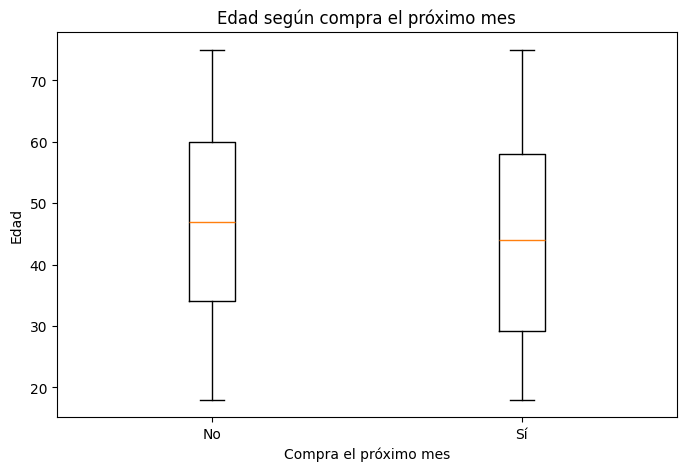

In [40]:
# TODO: primera visualización
# edad segun si compra o no (quito la edad de 195)
edad_ok = df[df['edad'] <= 120]
edad_no = edad_ok.loc[edad_ok['compra_proximo_mes'] == 'No', 'edad']
edad_si = edad_ok.loc[edad_ok['compra_proximo_mes'] == 'Sí', 'edad']

plt.figure(figsize=(8,5))
plt.boxplot([edad_no, edad_si], tick_labels=['No', 'Sí'])
plt.xlabel('Compra el próximo mes')
plt.ylabel('Edad')
plt.title('Edad según compra el próximo mes')
plt.show()

In [41]:
# TODO: comparación categórica y tabla de proporciones
for col in ['nivel_fidelidad', 'dispositivo', 'zona']:
    print('% de compra según', col)
    print((pd.crosstab(df[col], df['compra_proximo_mes'], normalize='index') * 100).round(2))
    print()

% de compra según nivel_fidelidad
compra_proximo_mes     No     Sí
nivel_fidelidad                 
Bronce              69.14  30.86
Oro                 62.65  37.35
Plata               60.00  40.00
Platino             38.00  62.00

% de compra según dispositivo
compra_proximo_mes     No     Sí
dispositivo                     
Móvil               63.22  36.78
Ordenador           57.89  42.11
Tablet              64.00  36.00

% de compra según zona
compra_proximo_mes     No     Sí
zona                            
Centro              63.16  36.84
Este                64.04  35.96
Norte               54.43  45.57
Oeste               57.89  42.11
Sur                 67.50  32.50



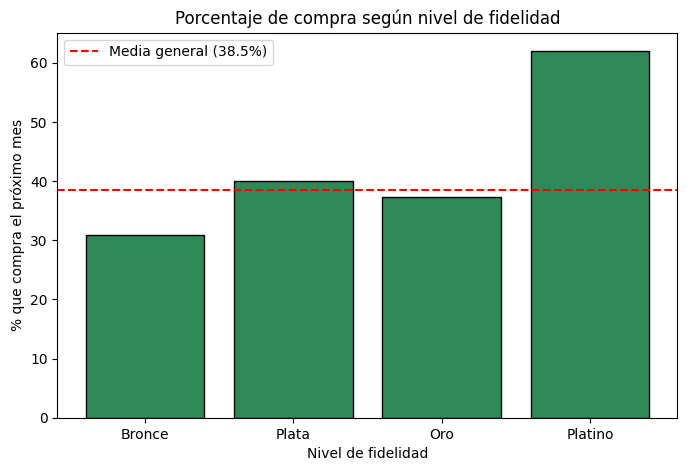

In [42]:
# TODO: segunda visualización
orden = ['Bronce', 'Plata', 'Oro', 'Platino']
pct_si = (pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'], normalize='index')['Sí'] * 100).reindex(orden)

plt.figure(figsize=(8,5))
plt.bar(pct_si.index, pct_si.values, color='seagreen', edgecolor='black')
plt.axhline(38.5, color='red', linestyle='--', label='Media general (38.5%)')
plt.xlabel('Nivel de fidelidad')
plt.ylabel('% que compra el próximo mes')
plt.title('Porcentaje de compra según nivel de fidelidad')
plt.legend()
plt.show()

### Interpretación del reto

Resume qué características parecen diferenciar a ambos grupos.

Distingue entre:

- lo que **observas** en el dataset
- lo que **no puedes concluir** a partir de esos datos.

**Respuesta:**

Lo que observo:

- Lo que más diferencia a los grupos es el nivel de fidelidad. En Bronce compra el 30.86% y en Platino el 62%.
- Los que compran gastaban más al mes (76.34 de media frente a 64.59).
- Los que compran son un poco más jóvenes (mediana 44 frente a 47.5).
- Por zona hay algo de diferencia (en el Norte compra el 45.57% y en el Sur el 32.5%) y por dispositivo el ordenador está un poco por encima.
- En ingresos, antigüedad, compras, devoluciones y satisfacción los dos grupos son casi iguales.

Lo que no puedo concluir:

- Que ninguna de estas cosas cause la compra, solo veo que van juntas.
- Que las diferencias pequeñas (zona, dispositivo, edad) sean reales y no casualidad, porque no he hecho ningún test y hay grupos con pocos clientes (25 con tablet, 50 en Platino).

# Parte 19 - Informe final de EDA

## Ejercicio 19

Selecciona los **5 hallazgos más relevantes**.

Para cada uno indica:

- **Pregunta:** ¿qué queríamos averiguar?
- **Evidencia:** ¿qué estadística, tabla o gráfico lo respalda?
- **Interpretación:** ¿qué hemos observado?
- **Limitación:** ¿qué no podemos concluir?

### Hallazgo 1
**Pregunta:** ¿El nivel de fidelidad tiene que ver con comprar el mes siguiente?
**Evidencia:** el crosstab normalizado por filas y el gráfico de barras del reto.
**Interpretación:** cuanto más alto el nivel más se compra: Bronce 30.86%, Oro 37.35%, Plata 40% y Platino 62%.
**Limitación:** es solo asociación, no sabemos si es el nivel lo que hace comprar. Además en Platino hay solo 50 clientes.

### Hallazgo 2
**Pregunta:** ¿Los que compran el mes siguiente gastaban más?
**Evidencia:** el groupby (media 76.34 frente a 64.59) y el boxplot por grupos.
**Interpretación:** sí, gastaban algo más y con más dispersión.
**Limitación:** los dos grupos se solapan bastante y la media se ve afectada por unos pocos gastos muy altos.

### Hallazgo 3
**Pregunta:** ¿Hay valores raros en los datos?
**Evidencia:** describe(), boxplots e IQR.
**Interpretación:** hay una edad de 195 años, que es un error, y 9 outliers en el gasto mensual (el mayor 260).
**Limitación:** el IQR no dice si un outlier está mal, los gastos altos pueden ser reales.

### Hallazgo 4
**Pregunta:** ¿Las variables numéricas están relacionadas entre sí?
**Evidencia:** la matriz de correlaciones y el imshow.
**Interpretación:** todas las correlaciones son muy bajas, ninguna pasa de 0.1. Por ejemplo compras y gasto -0.014 e ingresos y gasto casi 0.
**Limitación:** la correlación de Pearson solo ve relaciones lineales, puede haber otras que no detecta.

### Hallazgo 5
**Pregunta:** ¿Está equilibrado el target?
**Evidencia:** value_counts y el gráfico de barras de compra_proximo_mes.
**Interpretación:** no, el 61.5% no compra y el 38.5% sí.
**Limitación:** no sabemos si en otros meses sería igual. Habrá que tenerlo en cuenta al entrenar el modelo.

# Parte 20 - Conclusiones

## Ejercicio 20

Redacta unas conclusiones finales de entre **10 y 15 líneas**.

Incluye:

- características generales del dataset
- principales distribuciones
- posibles valores atípicos
- relaciones encontradas
- correlaciones relevantes
- diferencias entre grupos
- algún resultado que te haya sorprendido
- posibles problemas de calidad
- qué investigarías a continuación.

### Conclusiones

El dataset tiene 400 clientes y 12 columnas. cliente_id es el identificador y compra_proximo_mes el target, que está algo desequilibrado (61.5% No y 38.5% Sí).

El gasto mensual tiene cola hacia la derecha, con la media (69.09) por encima de la mediana (61.17). Los ingresos y el número de compras salen bastante simétricos. La mayoría compra desde el móvil y el nivel más común es Bronce.

He encontrado 9 outliers en el gasto mensual y una edad de 195 años que tiene que ser un error. Las correlaciones entre las variables numéricas son todas muy bajas, y lo que más me ha sorprendido es que los ingresos no tienen nada que ver con lo que se gasta al mes.

Donde sí se ve diferencia es en el nivel de fidelidad, en Platino compra el 62% y en Bronce el 30.86%. Los que compran también gastaban algo más de media.

Como problemas de calidad están la edad de 195, los 12 valores que faltan (antigüedad, ingresos y gasto) y que hay muchos clientes con 9000 de ingresos exactos, que parece un valor puesto por defecto. Lo siguiente que haría sería revisar esos datos, comprobar con algún test si las diferencias entre grupos son significativas y preparar los datos para entrenar un modelo.

# Antes de entregar

Comprueba que:

- [ ] Has completado todos los ejercicios.
- [ ] Has respondido las preguntas en Markdown.
- [ ] Todos los gráficos tienen título.
- [ ] Los ejes están correctamente identificados.
- [ ] Has interpretado los resultados.
- [ ] Has diferenciado correlación de causalidad.
- [ ] No has eliminado automáticamente los outliers.
- [ ] Has ejecutado el notebook completo desde el principio sin errores.

**Nombre recomendado:** `Practica_05_Apellido_Nombre.ipynb`